# Predicting Corporate Financial Distress from Financial-Statement Ratios

**Question:** Using only information a firm has already reported in fiscal year *t*, is it possible to flag which firms will be in financial distress in year *t+1*?

**Approach:** Ratio features built from LSEG (Refinitiv) fundamentals → logistic regression (baseline, L1, L2), random forest and gradient boosting, tuned with time-based grid search.

| Section | What it covers |
|---|---|
| 1 | The data: what it looks like and the cleaning / organizing challenges |
| 2 | Suitable algorithms and the hyperparameters to tune |
| 3 | Success criteria, with results |
| 4 | Where I need help / open questions |

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, roc_curve, precision_recall_curve)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# ---- modeling table built from LSEG data (one row per firm-fiscal-year) ----
m = pd.read_csv("../data/distress_model_data.csv", parse_dates=["PeriodEnd"])

feat = ["wc_ta", "re_ta", "ebit_ta", "mve_tl", "sales_ta", "tl_ta", "debt_ta", "cur_ratio",
        "cash_ta", "roa", "cfo_ta", "cov", "log_ta", "log_mc"]
print(f"{len(m):,} firm-years | {m['ric'].nunique():,} firms | fiscal years {int(m['fy'].min())}-{int(m['fy'].max())}")

17,164 firm-years | 1,908 firms | fiscal years 2007-2023


In [21]:
# Plain-English names for the features, used in plot labels
FEATURE_LABELS = {
    "wc_ta":      "Working capital / assets (short-term cushion)",
    "re_ta":      "Retained earnings / assets (past profits kept)",
    "ebit_ta":    "Operating profit / assets",
    "mve_tl":     "Market value / total liabilities (equity cushion)",
    "sales_ta":   "Sales / assets (how hard assets work)",
    "tl_ta":      "Total liabilities / assets (leverage)",
    "debt_ta":    "Debt / assets (borrowing)",
    "cur_ratio":  "Current ratio (short-term assets / short-term bills)",
    "cash_ta":    "Cash / assets",
    "roa":        "Net income / assets (return on assets)",
    "cfo_ta":     "Operating cash flow / assets",
    "cov":        "Interest coverage (operating profit / interest)",
    "log_ta":     "Size: total assets (log)",
    "log_mc":     "Size: market cap (log)",
    "distress_t": "Already distressed this year (yes/no)",
}

def nice(col):
    """Readable label for a feature, including the year-over-year change features."""
    if col.endswith("_chg"):
        return "1-yr change in " + FEATURE_LABELS.get(col[:-4], col[:-4])
    return FEATURE_LABELS.get(col, col)

---
# 1. The data

### Source and universe
- **Source:** LSEG Data Library (Refinitiv) annual fundamentals, pulled through the API: 19 line items per firm-year (balance sheet, income statement, cash flow, market cap) plus fiscal period-end and original announcement dates.
- **Universe:** every member of the **S&P 500, S&P 400 and S&P 600** (about 1,500 firms in any given year), 2007–2023.
- **Avoiding survivorship bias:** today's index list would contain only survivors, so I rebuilt membership *point-in-time* from the index joiner/leaver history, starting from today's list and undoing every change backward. The reconstruction stays within about 1–2% of the true index size every year. This brings in **1,328 retired tickers** (acquired, bankrupt, delisted), which the API exposes with a `^` suffix (e.g. `SHLD.OQ^J18`).
- **Excluded:** financials (banks and insurers have no meaningful current assets or working capital), and firm-years before a firm joined or after it left the index.

In [2]:
funnel = pd.DataFrame({
    "Step": ["Raw firm-years pulled from API (2,894 tickers)",
             "Valid period-end and total assets, de-duplicated, financials removed",
             "Firm was an index member in that fiscal year",
             "Has a t+1 label and complete features (FY2007-2023)"],
    "Rows": [42960, 35820, 22552, len(m)],
})
funnel["Dropped"] = (-funnel["Rows"].diff()).fillna(0).astype(int)
funnel

,Step,Rows,Dropped
0,"Raw firm-years pulled from API (2,894 tickers)",42960,0
1,"Valid period-end and total assets, de-duplicat...",35820,7140
2,Firm was an index member in that fiscal year,22552,13268
3,Has a t+1 label and complete features (FY2007-...,17164,5388


### What the modeling table looks like
Each row is one firm in one fiscal year. Columns are ratio features measured at year *t*, plus a label for year *t+1*.

In [28]:
show = ["ric", "PeriodEnd", "trbc_sector", "wc_ta", "re_ta", "ebit_ta", "mve_tl", "tl_ta", "cov", "distress_t", "label"]
show = [c for c in show if c in m.columns]
m[show].sample(8, random_state=1).round(3).rename(columns={**FEATURE_LABELS, "ric": "Ticker", "PeriodEnd": "Fiscal year end", "trbc_sector": "Sector", "label": "Distressed next year (label)"})

,Ticker,Fiscal year end,Sector,Working capital / assets (short-term cushion),Retained earnings / assets (past profits kept),Operating profit / assets,Market value / total liabilities (equity cushion),Total liabilities / assets (leverage),Interest coverage (operating profit / interest),Already distressed this year (yes/no),Distressed next year (label)
466,AGCO.N,2021-12-31,Industrials,0.170,0.564,0.111,1.367,0.625,40.028,0.0,0.0
13398,SANM.OQ,2017-09-30,Technology,0.260,-1.035,0.059,1.273,0.572,10.325,0.0,0.0
7529,HZO.N,2018-09-30,Consumer Cyclicals,0.280,0.259,0.099,1.995,0.449,6.380,0.0,0.0
3831,CSL.N,2012-12-31,Consumer Cyclicals,0.213,0.517,0.109,2.222,0.483,14.542,0.0,0.0
13785,SKYD.N,2018-12-31,Consumer Cyclicals,0.080,0.125,0.125,0.482,0.764,5.389,0.0,0.0
8097,JAKK.OQ,2012-12-31,Consumer Cyclicals,0.336,0.016,-0.024,0.793,0.627,-1.433,0.0,1.0
5044,ED.N,2013-12-31,Utilities,-0.021,0.205,0.058,0.570,0.699,4.061,0.0,0.0
5868,FELE.OQ,2020-12-31,Industrials,0.327,0.601,0.105,7.571,0.332,28.748,0.0,0.0


### Features (all measured at fiscal year *t*)
| Feature | Definition | Idea |
|---|---|---|
| `wc_ta` | (current assets − current liabilities) / assets | liquidity |
| `re_ta` | retained earnings / assets | cumulative profitability |
| `ebit_ta` | EBIT / assets | operating profitability |
| `mve_tl` | market cap / total liabilities | market-implied cushion |
| `sales_ta` | revenue / assets | asset turnover |
| `tl_ta`, `debt_ta` | total liabilities, total debt over assets | leverage |
| `cur_ratio`, `cash_ta` | current ratio; cash / assets | short-term liquidity |
| `roa`, `cfo_ta` | net income / assets; operating cash flow / assets | profitability, cash generation |
| `cov` | EBIT / interest expense (clipped at ±50) | debt-service capacity |
| `log_ta`, `log_mc` | log assets; log market cap | size |

The first five are the Altman Z-score ingredients, which gives us a classic benchmark to compare against.

### The label: distress in the *next* year
A firm-year is labeled **1** if in year *t+1* **EBIT < interest expense** (it does not cover its interest) **and** either operating cash flow is negative or total liabilities exceed total assets.
- **Features at year t, label at t+1** avoids leakage: the label is built from some of the same variables as the features, so using same-year values would make the problem circular.
- **Firms that disappear** have no next-year financials. For a retired ticker's last observed year, the delisting date is encoded in the ticker (`^G15` means July 2015). If it delisted within 18 months and its final year looked distressed (distress flag or liabilities > assets), it is labeled 1; if it was healthy (e.g. acquired), 0.

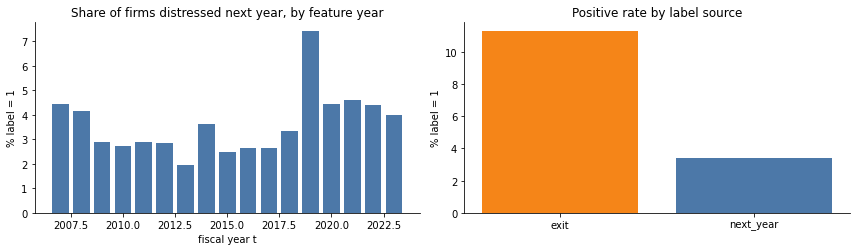

Positives: 625 of 17,164 (3.64%)  -> heavily imbalanced
P(distress next year | distressed now) = 56.7%  |  P(distress next year | healthy now) = 2.0%


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
by_year = m.groupby("fy")["label"].agg(["size", "sum", "mean"])
ax[0].bar(by_year.index, by_year["mean"] * 100, color="#4C78A8")
ax[0].set_title("Share of firms distressed next year, by feature year")
ax[0].set_ylabel("% label = 1"); ax[0].set_xlabel("fiscal year t")
if "label_src" in m.columns:
    s = m.groupby("label_src")["label"].agg(["size", "sum", "mean"])
    ax[1].bar(s.index, s["mean"] * 100, color=["#F58518", "#4C78A8"][:len(s)])
    ax[1].set_title("Positive rate by label source"); ax[1].set_ylabel("% label = 1")
plt.tight_layout(); plt.show()

print(f"Positives: {int(m['label'].sum()):,} of {len(m):,} ({m['label'].mean():.2%})  -> heavily imbalanced")
if "distress_t" in m.columns:
    print("P(distress next year | distressed now) = %.1f%%  |  P(distress next year | healthy now) = %.1f%%"
          % (100 * m.loc[m.distress_t == 1, 'label'].mean(), 100 * m.loc[m.distress_t == 0, 'label'].mean()))

**Reading the plots:** distress is rare (~3-4% of firm-years) and clusters around known stress periods (2007-09; the 2019 feature year, i.e. COVID in 2020). Roughly half of distressed firms are still distressed a year later, so a naive "same as last year" rule is a strong baseline. The more useful question is catching firms *before* they become distressed, which can also be reported.

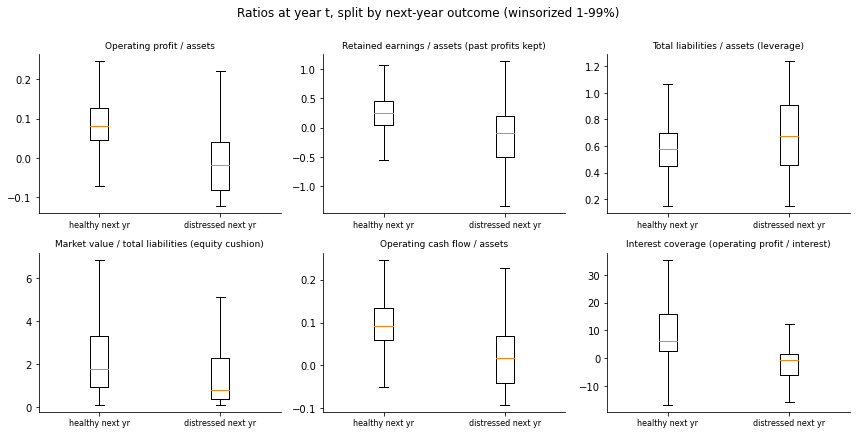

In [22]:
plot_feats = ["ebit_ta", "re_ta", "tl_ta", "mve_tl", "cfo_ta", "cov"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for a, f in zip(axes.ravel(), plot_feats):
    lo, hi = m[f].quantile([0.01, 0.99])
    data = [m.loc[m.label == k, f].clip(lo, hi).dropna() for k in (0, 1)]
    a.boxplot(data, showfliers=False)
    a.set_xticklabels(["healthy next yr", "distressed next yr"], fontsize=8)
    a.set_title(nice(f), fontsize=9)
plt.suptitle("Ratios at year t, split by next-year outcome (winsorized 1-99%)", y=1.0)
plt.tight_layout(); plt.show()

### Cleaning and organizing challenges
1. **Survivorship bias.** `0#.SPX(date)` simlpy returns *today's* constituents; the index list at a past date had to be reconstructed from joiner/leaver events. Ordering mattered as undoing changes oldest-first inflated index sizes to ~660 vs 500 until I processed them newest-first.
2. **Retired tickers.** Delisted firms only resolve under caret-suffixed RICs (e.g. `LEH.N^I08`); using the plain ticker fails. 34 retired tickers (about 1%) have no financial data at all (e.g. Lehman Brothers).
3. **Field discovery.** A few of the line items like receivables and inventory had only 3% and 63% coverage respectively (structurally missing for service firms), so both were dropped.
4. **Unavailability of data is not a distress signal.** Coverage for retired vs active firms differs by only 2-4 points (e.g. revenue 96.5% vs 99.3%).
5. **Timing.** Fiscal years end in different months and results are announced weeks later, so each row keeps both the period-end and the original announcement date for point-in-time alignment.
6. **Sector is today's classification**, not historical.

---
# 2. Suitable algorithms and hyperparameters

**Why logistic regression first:** the target is binary and imbalanced, the features are interpretable financial ratios, and a transparent model (coefficients = ratio effects) is easy to defend. It is also the classic form of distress models (Ohlson 1980).

| Model | Hyperparameter(s) to tune | Notes |
|---|---|---|
| Logistic regression, near-unregularized (baseline) | none (C = 10⁶) | reference point |
| Logistic regression + **L1** (lasso) | `C` (inverse regularization strength), grid 10⁻³ to 10² | does feature selection; ratios are correlated |
| Logistic regression + **L2** (ridge) | `C`, same grid | shrinks correlated ratios together |
| *Next:* Random forest / gradient boosting | `n_estimators`, `max_depth`, `learning_rate`, `min_samples_leaf` | can capture nonlinearities and interactions |

**Imbalance:** `class_weight="balanced"` in every model.

**Validation that based on time:**
- **Train:** feature years 2007-2016. **Test:** feature years 2017-2023, untouched until the end.
- **Tuning inside training:** forward-chaining folds. Validate on 2011, then 2012, ..., 2016, always training only on earlier years. Grid search on ROC-AUC.

In [6]:
class Winsor(BaseEstimator, TransformerMixin):
    def __init__(self, lo=1, hi=99): self.lo, self.hi = lo, hi
    def fit(self, X, y=None):
        X = np.asarray(X, float)
        self.lo_, self.hi_ = np.nanpercentile(X, self.lo, axis=0), np.nanpercentile(X, self.hi, axis=0)
        return self
    def transform(self, X): return np.clip(np.asarray(X, float), self.lo_, self.hi_)

TRAIN_END = 2016
train = m[m["fy"] <= TRAIN_END].reset_index(drop=True)
test  = m[m["fy"] >  TRAIN_END].reset_index(drop=True)
Xtr, ytr = train[feat], train["label"].astype(int)
Xte, yte = test[feat],  test["label"].astype(int)
print(f"train: {len(train):,} rows, {ytr.sum()} positives (FY<= {TRAIN_END})")
print(f"test : {len(test):,} rows, {yte.sum()} positives (FY>  {TRAIN_END})")

# forward-chaining folds: validate on 2011..2016 using only earlier years for training
folds = [(np.where(train["fy"] < v)[0], np.where(train["fy"] == v)[0]) for v in range(2011, TRAIN_END + 1)]

def make(penalty, solver):
    return Pipeline([("win", Winsor()), ("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                     ("lr", LogisticRegression(penalty=penalty, solver=solver, class_weight="balanced", max_iter=5000))])

Cs = np.logspace(-3, 2, 11)
specs = {
    "Baseline (no reg.)": (make("l2", "lbfgs"),     {"lr__C": [1e6]}),
    "L1 (lasso)":         (make("l1", "liblinear"), {"lr__C": Cs}),
    "L2 (ridge)":         (make("l2", "lbfgs"),     {"lr__C": Cs}),
}
fitted = {}
for name, (pipe, grid) in specs.items():
    gs = GridSearchCV(pipe, grid, cv=folds, scoring={"roc_auc": "roc_auc", "ap": "average_precision"},
                      refit="roc_auc", n_jobs=-1)
    gs.fit(Xtr, ytr)
    fitted[name] = gs
    print(f"{name:20s} best C = {gs.best_params_['lr__C']:<10.4g} CV ROC-AUC = {gs.cv_results_['mean_test_roc_auc'][gs.best_index_]:.3f}")

train: 9,707 rows, 296 positives (FY<= 2016)
test : 7,457 rows, 329 positives (FY>  2016)
Baseline (no reg.)   best C = 1e+06      CV ROC-AUC = 0.929
L1 (lasso)           best C = 0.01       CV ROC-AUC = 0.933
L2 (ridge)           best C = 0.003162   CV ROC-AUC = 0.930


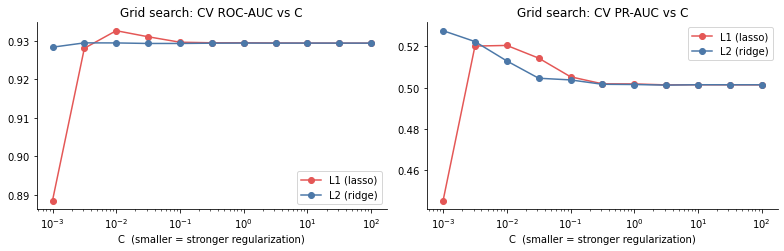

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for name, color in [("L1 (lasso)", "#E45756"), ("L2 (ridge)", "#4C78A8")]:
    r = fitted[name].cv_results_
    ax[0].semilogx(Cs, r["mean_test_roc_auc"], "o-", color=color, label=name)
    ax[1].semilogx(Cs, r["mean_test_ap"], "o-", color=color, label=name)
ax[0].set_title("Grid search: CV ROC-AUC vs C"); ax[1].set_title("Grid search: CV PR-AUC vs C")
for a in ax: a.set_xlabel("C  (smaller = stronger regularization)"); a.legend()
plt.tight_layout(); plt.show()

---
# 3. Success criteria and results

With ~3-4% positives, accuracy is meaningless (predicting "healthy" for everyone scores ~96%). Criteria on the **held-out 2017-2023 test period**:

| Metric | Why |
|---|---|
| **ROC-AUC** | ranking quality across all thresholds |
| **Precision, recall, F1** | at a fixed threshold: false alarms vs missed distress |
| **Recall in the riskiest 5%** | if an analyst can only review the top 5% of scores, how many distressed firms are caught? |
| **ROC-AUC on currently healthy firms only** | the honest early-warning test: can firms get flagged *before* they are already distressed? |

**Benchmarks:** (1) *persistence*: predict distress next year if distressed now; (2) the **Altman Z-score** (1968) from the same five ratios, with the classic cutoff Z < 1.81.

In [8]:
def topk(y, s, frac=0.05):
    k = max(1, int(len(y) * frac)); idx = np.argsort(-s)[:k]
    return y.values[idx].sum() / max(y.sum(), 1), y.values[idx].mean()

def evaluate(name, s, thr, mask=None):
    p = (s >= thr).astype(int)
    rec5, prec5 = topk(yte, s)
    r = {"Model": name,
         "ROC-AUC": roc_auc_score(yte, s), "PR-AUC": average_precision_score(yte, s),
         "Precision": precision_score(yte, p, zero_division=0), "Recall": recall_score(yte, p),
         "F1": f1_score(yte, p), "Recall @ top 5%": rec5}
    if mask is not None:
        r["ROC-AUC (healthy now)"] = roc_auc_score(yte[mask], s[mask])
    return r

healthy = (test["distress_t"] == 0).values
scores = {name: gs.predict_proba(Xte)[:, 1] for name, gs in fitted.items()}
rows = [evaluate(n, s, 0.5, healthy) for n, s in scores.items()]

# benchmark 1: persistence
pers = test["distress_t"].fillna(0).values.astype(float)
r = evaluate("Persistence (same as last yr)", pers, 0.5); r["ROC-AUC (healthy now)"] = np.nan; rows.append(r)

# benchmark 2: Altman Z (higher Z = safer, so use -Z as the risk score; classic cutoff Z < 1.81)
Z = (1.2*test["wc_ta"] + 1.4*test["re_ta"] + 3.3*test["ebit_ta"] + 0.6*test["mve_tl"] + 1.0*test["sales_ta"])
Z = Z.fillna(Z.median()).values
rz = evaluate("Altman Z-score (1968)", -Z, -1.81, healthy)
rows.append(rz)

results = pd.DataFrame(rows).set_index("Model").round(3)
results

,ROC-AUC,PR-AUC,Precision,Recall,F1,Recall @ top 5%,ROC-AUC (healthy now)
Model,,,,,,,
Baseline (no reg.),0.888,0.431,0.203,0.736,0.318,0.474,0.819
L1 (lasso),0.884,0.442,0.203,0.757,0.320,0.474,0.811
L2 (ridge),0.884,0.450,0.213,0.751,0.332,0.486,0.807
Persistence (same as last yr),0.741,0.312,0.582,0.498,0.537,0.502,NaN
Altman Z-score (1968),0.703,0.151,0.088,0.596,0.153,0.252,0.615


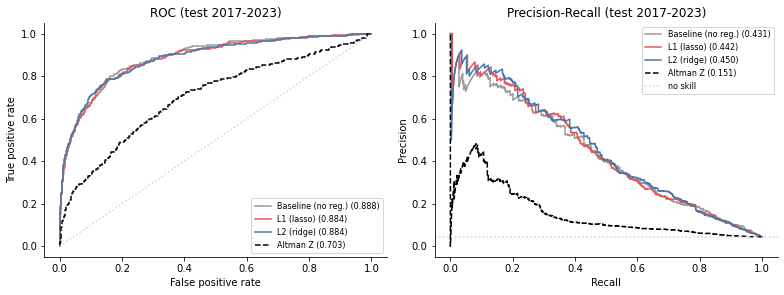

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
cols = {"Baseline (no reg.)": "#999999", "L1 (lasso)": "#E45756", "L2 (ridge)": "#4C78A8"}
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(yte, s); ax[0].plot(fpr, tpr, color=cols[name], label=f"{name} ({roc_auc_score(yte, s):.3f})")
    pr, rc, _ = precision_recall_curve(yte, s); ax[1].plot(rc, pr, color=cols[name], label=f"{name} ({average_precision_score(yte, s):.3f})")
fpr, tpr, _ = roc_curve(yte, -Z); ax[0].plot(fpr, tpr, "k--", label=f"Altman Z ({roc_auc_score(yte, -Z):.3f})")
pr, rc, _ = precision_recall_curve(yte, -Z); ax[1].plot(rc, pr, "k--", label=f"Altman Z ({average_precision_score(yte, -Z):.3f})")
ax[0].plot([0, 1], [0, 1], ":", color="lightgrey"); ax[1].axhline(yte.mean(), ls=":", color="lightgrey", label="no skill")
ax[0].set_title("ROC (test 2017-2023)"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[1].set_title("Precision-Recall (test 2017-2023)"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Financial ratios / metrics that matter
Coefficients are on standardized features, so they are comparable in size. Positive = higher risk of next-year distress.

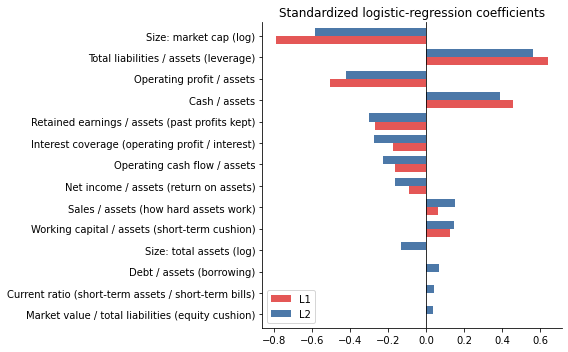

L1 keeps 10 of 14 features (best C = 0.01)


In [23]:
best = fitted["L1 (lasso)"].best_estimator_.named_steps["lr"]
coef = pd.DataFrame({"L1": best.coef_[0],
                     "L2": fitted["L2 (ridge)"].best_estimator_.named_steps["lr"].coef_[0]}, index=[nice(f) for f in feat])
coef = coef.loc[coef["L2"].abs().sort_values().index]
ax = coef.plot.barh(figsize=(8, 5), color=["#E45756", "#4C78A8"], width=0.75)
ax.axvline(0, color="k", lw=0.8); ax.set_title("Standardized logistic-regression coefficients")
plt.tight_layout(); plt.show()
print(f"L1 keeps {(coef['L1'] != 0).sum()} of {len(feat)} features (best C = {fitted['L1 (lasso)'].best_params_['lr__C']:.3g})")

### Does performance hold up over time?
Test-period ROC-AUC for the best model, one feature year at a time (the 2019 feature year is the COVID shock).

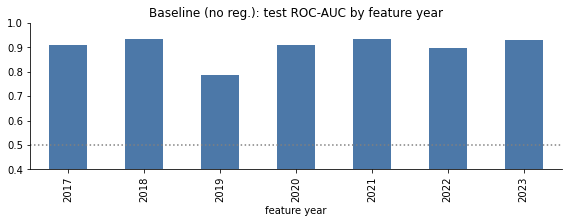

feature year,2017,2018,2019,2020,2021,2022,2023
ROC-AUC,0.911,0.935,0.786,0.908,0.933,0.897,0.93
positives,27.000,35.000,78.000,47.000,50.000,48.000,44.00


In [11]:
best_name = results.loc[[n for n in results.index if n in fitted], "ROC-AUC"].idxmax()
s_best = scores[best_name]
by = []
for y in sorted(test["fy"].unique()):
    k = (test["fy"] == y).values
    if yte[k].sum() >= 5:
        by.append((int(y), roc_auc_score(yte[k], s_best[k]), int(yte[k].sum())))
by = pd.DataFrame(by, columns=["feature year", "ROC-AUC", "positives"]).set_index("feature year")
ax = by["ROC-AUC"].plot.bar(figsize=(8, 3.2), color="#4C78A8"); ax.set_ylim(0.4, 1.0); ax.axhline(0.5, color="grey", ls=":")
ax.set_title(f"{best_name}: test ROC-AUC by feature year"); plt.tight_layout(); plt.show()
by.round(3).T

In [12]:
# auto-generated summary of the results above
b = results.loc[best_name]; pz = results.loc["Persistence (same as last yr)"]; az = results.loc["Altman Z-score (1968)"]
print(f"Best logistic model on the test period: {best_name}")
print(f"  ROC-AUC {b['ROC-AUC']:.3f} | PR-AUC {b['PR-AUC']:.3f} | recall in riskiest 5%: {b['Recall @ top 5%']:.1%}")
print(f"  Among currently healthy firms only: ROC-AUC {b['ROC-AUC (healthy now)']:.3f}")
print(f"  vs Altman Z: ROC-AUC {az['ROC-AUC']:.3f} (healthy-now {az['ROC-AUC (healthy now)']:.3f}) | vs persistence: ROC-AUC {pz['ROC-AUC']:.3f}")
print(f"  Base rate of distress in test period: {yte.mean():.1%} (PR-AUC of a no-skill model)")

Best logistic model on the test period: Baseline (no reg.)
  ROC-AUC 0.888 | PR-AUC 0.431 | recall in riskiest 5%: 47.4%
  Among currently healthy firms only: ROC-AUC 0.819
  vs Altman Z: ROC-AUC 0.703 (healthy-now 0.615) | vs persistence: ROC-AUC 0.741
  Base rate of distress in test period: 4.4% (PR-AUC of a no-skill model)


## 5. Improvements: tree-based models and ratio-momentum features
 
Two changes, both listed as next steps above:
 
1. **Random forest and gradient boosting.** Trees can pick up nonlinear effects
   (e.g. coverage only matters once it falls below ~1x) and interactions
   (high leverage is dangerous *when* cash flow is negative) that a linear
   logit cannot.
2. **Year-over-year change features.** A firm whose EBIT/assets fell from 8% to 1%
   is riskier than one sitting steadily at 1%. I add the one-year change in key
   ratios, plus the current-year distress flag (it is known at year t, and
   persistence showed it carries signal).
 
Same rules as before: train on feature years 2007-2016, tune on the same
forward-chaining folds (validate 2011, ..., 2016), and touch the 2017-2023 test
set only once at the end. **The final model is picked by CV score, not test score.**

In [13]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
 
# HiPerGator: os.cpu_count() reports the whole node (e.g. 128), not the cores your session was given.
# n_jobs=-1 would start far too many workers, so use the real allocation (falls back to 4).
N_JOBS = int(os.environ.get("SLURM_CPUS_ON_NODE", 4))
print(f"Using n_jobs = {N_JOBS}")
 
chg_base = ["ebit_ta", "roa", "cfo_ta", "tl_ta", "debt_ta", "cov", "wc_ta", "cash_ta", "mve_tl", "log_mc"]
 
# previous fiscal year's values for the same firm (only if that year is exactly fy-1)
lag = (m[["ric", "fy"] + chg_base].drop_duplicates(["ric", "fy"])
         .assign(fy=lambda d: d["fy"] + 1)
         .rename(columns={c: c + "_lag" for c in chg_base}))
mm = m.merge(lag, on=["ric", "fy"], how="left")          # left merge keeps m's row order
assert len(mm) == len(m) and (mm["ric"].values == m["ric"].values).all()
 
for c in chg_base:
    mm[c + "_chg"] = mm[c] - mm[c + "_lag"]
 
chg_feat = [c + "_chg" for c in chg_base]
feat_ext = feat + chg_feat + ["distress_t"]
 
# rebuild train/test exactly as before (same rows, same order -> same folds, same yte)
train2 = mm[mm["fy"] <= TRAIN_END].reset_index(drop=True)
test2  = mm[mm["fy"] >  TRAIN_END].reset_index(drop=True)
assert (train2["label"].values == train["label"].values).all() and (test2["label"].values == test["label"].values).all()
 
cov_chg = mm[chg_feat].notna().mean().mean()
print(f"Added {len(chg_feat)} change features + distress_t -> {len(feat_ext)} features total")
print(f"Change features available for {cov_chg:.0%} of firm-years (missing = firm's first year in the sample)")

Using n_jobs = 2
Added 10 change features + distress_t -> 25 features total
Change features available for 87% of firm-years (missing = firm's first year in the sample)


### Hyperparameters tuned

| Model | Grid | What it controls |
|---|---|---|
| Random forest | `n_estimators` {200}, `max_depth` {8, none}, `min_samples_leaf` {20, 50}, `max_features` {sqrt} | depth and leaf size limit how much each tree can overfit; `max_features` controls how decorrelated the trees are |
| Gradient boosting | `n_estimators` {200}, `learning_rate` {0.05, 0.1}, `max_depth` {3}, `subsample` {0.8} | number of trees × step size sets how closely boosting fits the data; depth sets the interaction order; subsampling adds randomness that reduces overfitting |

The grids are deliberately small so the full search runs quickly.

**Imbalance.** Same approach as the logistic models: class-balanced weights. Random forest uses `class_weight="balanced"`. `GradientBoostingClassifier` has no `class_weight` option, so it receives the same balanced weights through `sample_weight`. Trees don't need scaling or winsorizing, so missing values are only median-imputed.

In [14]:
def make_rf():
    return Pipeline([("imp", SimpleImputer(strategy="median")),
                     ("rf", RandomForestClassifier(class_weight="balanced", n_jobs=1, random_state=42))])
 
def make_gb():
    return Pipeline([("imp", SimpleImputer(strategy="median")),
                     ("gb", GradientBoostingClassifier(random_state=42))])
 
rf_grid = {"rf__n_estimators": [200], "rf__max_depth": [8, None],
           "rf__min_samples_leaf": [20, 50], "rf__max_features": ["sqrt"]}
gb_grid = {"gb__n_estimators": [200], "gb__learning_rate": [0.05, 0.1],
           "gb__max_depth": [3], "gb__subsample": [0.8]}
 
tree_specs = {
    "Random forest":                  (make_rf(), rf_grid, feat),
    "Gradient boosting":              (make_gb(), gb_grid, feat),
    "Random forest + changes":        (make_rf(), rf_grid, feat_ext),
    "Gradient boosting + changes":    (make_gb(), gb_grid, feat_ext),
}
 
w_tr = compute_sample_weight("balanced", ytr)
tree_fitted, tree_feats = {}, {}
for name, (pipe, grid, cols) in tree_specs.items():
    gs = GridSearchCV(pipe, grid, cv=folds, scoring={"roc_auc": "roc_auc", "ap": "average_precision"},
                      refit="roc_auc", n_jobs=N_JOBS)
    fit_kw = {"gb__sample_weight": w_tr} if "gb" in pipe.named_steps else {}
    gs.fit(train2[cols], ytr, **fit_kw)
    tree_fitted[name], tree_feats[name] = gs, cols
    best = {k.split("__")[1]: v for k, v in gs.best_params_.items()}
    print(f"{name:30s} CV ROC-AUC = {gs.cv_results_['mean_test_roc_auc'][gs.best_index_]:.3f}"
          f"  CV PR-AUC = {gs.cv_results_['mean_test_ap'][gs.best_index_]:.3f}   best: {best}")
 
# for a fair comparison, also refit the best logistic model (L1) on the extended features
lr_ext = GridSearchCV(make("l1", "liblinear"), {"lr__C": Cs}, cv=folds,
                      scoring={"roc_auc": "roc_auc", "ap": "average_precision"}, refit="roc_auc", n_jobs=N_JOBS)
lr_ext.fit(train2[feat_ext], ytr)
tree_fitted["L1 (lasso) + changes"], tree_feats["L1 (lasso) + changes"] = lr_ext, feat_ext
print(f"{'L1 (lasso) + changes':30s} CV ROC-AUC = {lr_ext.cv_results_['mean_test_roc_auc'][lr_ext.best_index_]:.3f}"
      f"  CV PR-AUC = {lr_ext.cv_results_['mean_test_ap'][lr_ext.best_index_]:.3f}")

Random forest                  CV ROC-AUC = 0.951  CV PR-AUC = 0.538   best: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 20, 'n_estimators': 200}
Gradient boosting              CV ROC-AUC = 0.942  CV PR-AUC = 0.453   best: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}
Random forest + changes        CV ROC-AUC = 0.951  CV PR-AUC = 0.530   best: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 20, 'n_estimators': 200}
Gradient boosting + changes    CV ROC-AUC = 0.942  CV PR-AUC = 0.461   best: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}
L1 (lasso) + changes           CV ROC-AUC = 0.942  CV PR-AUC = 0.538


In [15]:
new_scores = {name: gs.predict_proba(test2[tree_feats[name]])[:, 1] for name, gs in tree_fitted.items()}
new_rows = [evaluate(n, s, 0.5, healthy) for n, s in new_scores.items()]
 
# CV score of every model (what we are allowed to choose on)
cv_auc = {n: g.cv_results_["mean_test_roc_auc"][g.best_index_] for n, g in {**fitted, **tree_fitted}.items()}
 
all_results = pd.concat([results, pd.DataFrame(new_rows).set_index("Model").round(3)])
all_results.insert(0, "CV ROC-AUC", pd.Series(cv_auc).round(3))
all_results = all_results.sort_values("CV ROC-AUC", ascending=False, na_position="last")
 
# model chosen by cross-validation (NOT by test score)
final_name = max(tree_fitted, key=lambda n: cv_auc[n])
print(f"Model selected by CV: {final_name}\n")
all_results.style.format("{:.3f}", na_rep="-").highlight_max(
    subset=[c for c in all_results.columns if c not in ("Precision",)], color="#d4edda")

Model selected by CV: Random forest + changes



,CV ROC-AUC,ROC-AUC,PR-AUC,Precision,Recall,F1,Recall @ top 5%,ROC-AUC (healthy now)
Model,,,,,,,,
Random forest,0.951,0.898,0.516,0.341,0.696,0.458,0.553,0.818
Random forest + changes,0.951,0.905,0.527,0.362,0.675,0.471,0.587,0.829
Gradient boosting,0.942,0.894,0.490,0.297,0.736,0.423,0.541,0.813
Gradient boosting + changes,0.942,0.902,0.502,0.288,0.717,0.411,0.529,0.827
L1 (lasso) + changes,0.942,0.895,0.511,0.234,0.739,0.355,0.550,0.809
L1 (lasso),0.933,0.884,0.442,0.203,0.757,0.320,0.474,0.811
L2 (ridge),0.930,0.884,0.450,0.213,0.751,0.332,0.486,0.807
Baseline (no reg.),0.929,0.888,0.431,0.203,0.736,0.318,0.474,0.819
Persistence (same as last yr),-,0.741,0.312,0.582,0.498,0.537,0.502,-


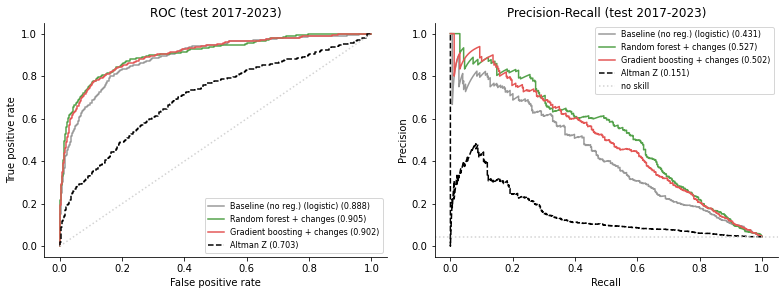

In [16]:
lr_best = results.loc[[n for n in results.index if n in fitted], "ROC-AUC"].idxmax()
curves = {f"{lr_best} (logistic)": (scores[lr_best], "#999999", "-"),
          "Random forest + changes": (new_scores["Random forest + changes"], "#54A24B", "-"),
          "Gradient boosting + changes": (new_scores["Gradient boosting + changes"], "#E45756", "-"),
          "Altman Z": (-Z, "k", "--")}
 
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for name, (s, c, ls) in curves.items():
    fpr, tpr, _ = roc_curve(yte, s); ax[0].plot(fpr, tpr, color=c, ls=ls, label=f"{name} ({roc_auc_score(yte, s):.3f})")
    pr, rc, _ = precision_recall_curve(yte, s); ax[1].plot(rc, pr, color=c, ls=ls, label=f"{name} ({average_precision_score(yte, s):.3f})")
ax[0].plot([0, 1], [0, 1], ":", color="lightgrey"); ax[1].axhline(yte.mean(), ls=":", color="lightgrey", label="no skill")
ax[0].set_title("ROC (test 2017-2023)"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[1].set_title("Precision-Recall (test 2017-2023)"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
for a in ax: a.legend(fontsize=8)
plt.tight_layout()
os.makedirs("../figures", exist_ok=True)
plt.savefig("../figures/model_comparison.png", dpi=150, bbox_inches="tight")   # for the GitHub README
plt.show()

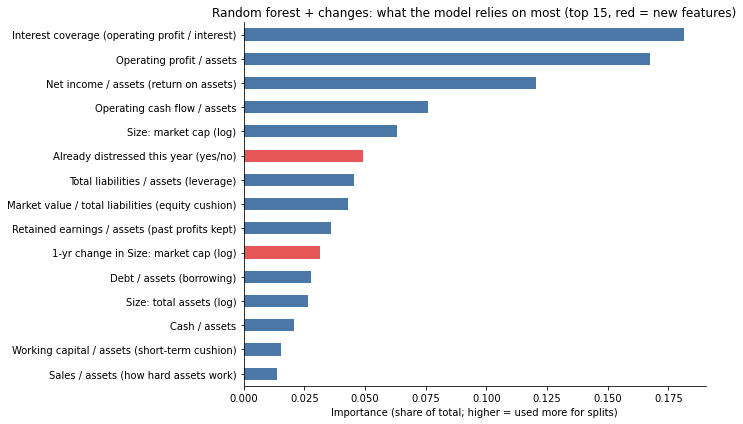

In [24]:
# Built-in tree importance (mean decrease in impurity, MDI): how much each feature reduces
# impurity across all splits, averaged over the trees. Shown for the best tree model by CV score.
# Caveat: MDI is computed on training data and favors continuous features with
# many split points, so read it as a ranking, not an exact measure.
best_tree = max([n for n in tree_fitted if "lasso" not in n], key=lambda n: cv_auc[n])
est = tree_fitted[best_tree].best_estimator_[-1]          # last pipeline step = the forest / booster
imp = pd.Series(est.feature_importances_, index=tree_feats[best_tree]).sort_values()

top = imp.tail(15)
colors = ["#E45756" if c.endswith("_chg") or c == "distress_t" else "#4C78A8" for c in top.index]
top.index = [nice(c) for c in top.index]
ax = top.plot.barh(figsize=(10, 6), color=colors)
ax.set_title(f"{best_tree}: what the model relies on most (top 15, red = new features)")
ax.set_xlabel("Importance (share of total; higher = used more for splits)")
plt.tight_layout(); plt.show()

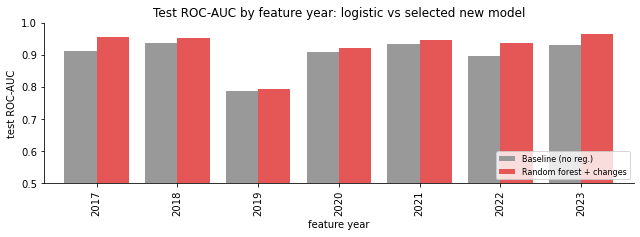

feature year,2017,2018,2019,2020,2021,2022,2023
Baseline (no reg.),0.911,0.935,0.786,0.908,0.933,0.897,0.930
Random forest + changes,0.954,0.951,0.793,0.920,0.946,0.937,0.966


In [25]:
s_new = new_scores[final_name]
rows_y = []
for y in sorted(test2["fy"].unique()):
    k = (test2["fy"] == y).values
    if yte[k].sum() >= 5:
        rows_y.append((int(y), roc_auc_score(yte[k], scores[lr_best][k]), roc_auc_score(yte[k], s_new[k])))
by2 = pd.DataFrame(rows_y, columns=["feature year", lr_best, final_name]).set_index("feature year")
 
ax = by2.plot.bar(figsize=(9, 3.4), color=["#999999", "#E45756"], width=0.8)
ax.set_ylim(0.5, 1.0); ax.set_ylabel("test ROC-AUC")
ax.set_title("Test ROC-AUC by feature year: logistic vs selected new model")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()
by2.round(3).T

In [26]:
def watchlist(s, frac=0.05):
    """Flag the top `frac` of scores within each feature year; return recall and precision."""
    flag = np.zeros(len(s), bool)
    for y in test2["fy"].unique():
        k = np.where(test2["fy"].values == y)[0]
        n = max(1, int(len(k) * frac)); flag[k[np.argsort(-s[k])[:n]]] = True
    caught = yte.values[flag].sum()
    return caught, yte.sum(), caught / yte.sum(), yte.values[flag].mean()
 
wl = []
for name, s in [(f"{lr_best} (logistic)", scores[lr_best]), (final_name, s_new), ("Altman Z", -Z)]:
    c, tot, rec, prec = watchlist(s)
    wl.append({"Model": name, "Distressed firms caught": f"{c} of {tot}", "Recall": rec, "Precision of watchlist": prec})
pd.DataFrame(wl).set_index("Model").style.format({"Recall": "{:.1%}", "Precision of watchlist": "{:.1%}"})

,Distressed firms caught,Recall,Precision of watchlist
Model,,,
Baseline (no reg.) (logistic),157 of 329,47.7%,42.3%
Random forest + changes,189 of 329,57.4%,50.9%
Altman Z,82 of 329,24.9%,22.1%


In [27]:
old, new = all_results.loc[lr_best], all_results.loc[final_name]
print(f"Selected by cross-validation: {final_name}")
print(f"  Test ROC-AUC            {old['ROC-AUC']:.3f} -> {new['ROC-AUC']:.3f}  ({new['ROC-AUC'] - old['ROC-AUC']:+.3f})")
print(f"  Test PR-AUC             {old['PR-AUC']:.3f} -> {new['PR-AUC']:.3f}  ({new['PR-AUC'] - old['PR-AUC']:+.3f})")
print(f"  Recall in riskiest 5%   {old['Recall @ top 5%']:.1%} -> {new['Recall @ top 5%']:.1%}")
print(f"  ROC-AUC, healthy now    {old['ROC-AUC (healthy now)']:.3f} -> {new['ROC-AUC (healthy now)']:.3f}")
print(f"  (old = best logistic model, {lr_best}; Altman Z test ROC-AUC = {all_results.loc['Altman Z-score (1968)', 'ROC-AUC']:.3f})")

Selected by cross-validation: Random forest + changes
  Test ROC-AUC            0.888 -> 0.905  (+0.017)
  Test PR-AUC             0.431 -> 0.527  (+0.096)
  Recall in riskiest 5%   47.4% -> 58.7%
  ROC-AUC, healthy now    0.819 -> 0.829
  (old = best logistic model, Baseline (no reg.); Altman Z test ROC-AUC = 0.703)


### What the improvements showed

| Test set, 2017-2023 | Best logistic (baseline) | Random forest + changes |
|---|---|---|
| ROC-AUC | 0.888 | **0.905** |
| PR-AUC | 0.431 | **0.527** |
| Distressed firms caught in the riskiest 5% each year | 157 of 329 (48%) | **189 of 329 (57%)** |
| Share of that watchlist actually distressed | 42% | **51%** |
| Precision / recall at the 0.5 cutoff | 20% / 74% | 36% / 68% |
| ROC-AUC, firms healthy today | 0.819 | 0.829 |

- **Trees beat logistic regression.** Both tree models outscored every logistic model in cross-validation (random forest 0.951, gradient boosting 0.942, best logistic 0.933), and the ranking held on the untouched test set. The gain is largest at the top of the risk ranking: PR-AUC rose 22%, and an analyst reviewing the riskiest 5% of firms each year would catch 32 more distressed firms, with about half of the flagged firms actually distressed. At the 0.5 cutoff, false alarms drop sharply (precision 20% → 36%) for a small loss in recall.
- **Random forest edged out gradient boosting** on both CV and test ROC-AUC. Boosting's grid was small, so it may be under-tuned.
- **The year-over-year change features added little.** Random forest scored 0.951 in CV with and without them, and the test gain (0.898 → 0.905) is within noise. Of the 11 new features, only the current-year distress flag and the change in log market cap reach the top 15 in importance. Most of the improvement comes from the nonlinear model, not from the new features. For lasso, the expanded feature set helped more (test ROC-AUC 0.884 → 0.895, PR-AUC 0.442 → 0.511); I have not separated how much of that comes from the distress flag versus the change features.
- **What drives the predictions:** interest coverage, EBIT/assets, ROA and cash flow/assets. These are close to the ingredients of the label itself (EBIT below interest expense, negative operating cash flow), so part of what the model learns is that weak coverage tends to persist. This is the circularity raised in Section 4.
- **Early warning barely improved.** Among firms that are healthy today, ROC-AUC moved only from 0.819 to 0.829, and random forest without the change features showed no gain (0.818). The improvement is concentrated in firms already showing stress; flagging healthy firms before they deteriorate remains the hard problem.
- **Consistent across years.** Random forest beats the logistic baseline in every test year, by 0.007 to 0.043 ROC-AUC. 2019 is still the weakest year for both models (0.793 vs 0.786): the 2020 COVID shock was not visible in 2019 financial statements.
- **Caveats.** The test window has only 329 distressed firm-years, so differences of about 0.01 in ROC-AUC are within noise. The model was selected on CV, where random forest with and without the change features tied at 0.951, so the simpler model without them is an equally defensible choice.